In [1]:
# Importing all necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

In [2]:
# Q4A

# 1. Load the Automobile MPG dataset
q4_dataset = pd.read_csv('datasets/Q4_automobile_mpg.csv')

# 2. Display the first and last five observations
print('First 5 observations:')
print(f'{q4_dataset.head(5)}\n')
print('Last 5 observations:')
print(f'{q4_dataset.tail(5)}\n')

# 3. Determine the number of rows and columns
print(f'Number of rows: {len(q4_dataset)}')
print(f'Number of columns: {len(q4_dataset.columns)}\n')

# 4. Display variable names and data types
for col in q4_dataset.columns:
    print(f'Variable: {col} | Data Type: {q4_dataset[col].dtype}')
print()

# 5. Identify numerical and categorical variables
# Note: 'origin' is coded as 1=USA, 2=Europe, 3=Japan, making it a categorical variable represented numerically
numeric_cols_q4 = q4_dataset.select_dtypes(include=['number']).columns.tolist()
categorical_cols_q4 = q4_dataset.select_dtypes(include=['object', 'str']).columns.tolist()

print(f'Initial Numerical columns (by dtype): {numeric_cols_q4}')
print(f'Initial Categorical/Object columns (by dtype): {categorical_cols_q4}')
print('Note: "horsepower" is stored as an object/string due to non-numeric characters ("?"), while "origin" (1=USA, 2=Europe, 3=Japan) is conceptually categorical.')

First 5 observations:
    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1              amc rebel sst  
4          70       1                ford torino  

Last 5 observations:
      mpg  cylinders  displacement  horsepower  weight  acceleration  \
393  27.0          4         140.0        86.0  2790.0          15.6   
394  44.0          4          97.0        52.0  2130.0          24.6   
395  32.0    

In [3]:
# Q4B

# 1 & 3. Check for missing values and numerical variables stored as strings/objects
print('Missing values per column (standard NaN check):')
print(f'{q4_dataset.isnull().sum()}\n')

# Check if horsepower is stored as object/string due to '?' characters
if q4_dataset['horsepower'].dtype == object or str(q4_dataset['horsepower'].dtype) == 'str':
    question_marks = (q4_dataset['horsepower'] == '?').sum()
    print(f'Column "horsepower" is stored as {q4_dataset["horsepower"].dtype} and contains {question_marks} "?" entries representing missing values.')

# 4. Correct inappropriate data types and handle missing values
q4_dataset['horsepower'] = pd.to_numeric(q4_dataset['horsepower'], errors='coerce')
missing_hp = q4_dataset['horsepower'].isnull().sum()
print(f'Total missing values in horsepower after type conversion: {missing_hp}')

print(f'Rows before dropping missing values: {len(q4_dataset)}')
q4_dataset = q4_dataset.dropna().reset_index(drop=True)
print(f'Rows after dropping missing values: {len(q4_dataset)}\n')

# 2. Check for duplicates
duplicates_q4 = q4_dataset.duplicated().sum()
print(f'Duplicate rows found: {duplicates_q4}')
if duplicates_q4 > 0:
    q4_dataset = q4_dataset.drop_duplicates(keep='first').reset_index(drop=True)
    print(f'Rows after removing duplicates: {len(q4_dataset)}\n')
else:
    print('No duplicate rows to remove.\n')

print('Updated Data Types:')
print(f'{q4_dataset.dtypes}\n')

# 5. Investigate outliers in mpg, horsepower, and weight using IQR
for col in ['mpg', 'horsepower', 'weight']:
    q25, q75 = np.percentile(q4_dataset[col], 25), np.percentile(q4_dataset[col], 75)
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    outliers = ((q4_dataset[col] < lower) | (q4_dataset[col] > upper)).sum()
    print(f'{col.upper()} -> Q1: {q25:.2f}, Q3: {q75:.2f}, IQR Bounds: [{lower:.2f}, {upper:.2f}], Outliers detected: {outliers}')
print()

# 6. Explain all data-cleaning decisions
print('Explanation of Data-Cleaning Decisions:')
print('1. The "horsepower" column was originally stored as a string/object because missing values were encoded as "?". '
      'It was converted to a float data type using pd.to_numeric().')
print('2. The rows with missing horsepower values were removed because they represent a very small fraction of the dataset (~1.5%) '
      'and removing them avoids introducing imputation bias into correlation and regression analyses.')
print('3. Outliers in mpg, horsepower, and weight were investigated using the 1.5*IQR rule. Very few extreme values exist, and they '
      'represent legitimate high-powered muscle cars or high-efficiency compact vehicles, so they were retained to preserve the true distribution of automobile specifications.')

Missing values per column (standard NaN check):
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Total missing values in horsepower after type conversion: 6
Rows before dropping missing values: 398
Rows after dropping missing values: 392

Duplicate rows found: 0
No duplicate rows to remove.

Updated Data Types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight          float64
acceleration    float64
model_year        int64
origin            int64
car_name            str
dtype: object

MPG -> Q1: 17.00, Q3: 29.00, IQR Bounds: [-1.00, 47.00], Outliers detected: 0
HORSEPOWER -> Q1: 75.00, Q3: 126.00, IQR Bounds: [-1.50, 202.50], Outliers detected: 10
WEIGHT -> Q1: 2225.25, Q3: 3614.75, IQR Bounds: [141.00, 5699.00], Outliers detected: 0

Explanation of Data-Cleaning Decisions:
1. The "horsepower" column was ori

In [4]:
# Q4C

# 1. Calculate descriptive statistics for mpg, horsepower, weight, and acceleration
print('Descriptive Statistics for MPG, Horsepower, Weight, and Acceleration:')
print(f"{q4_dataset[['mpg', 'horsepower', 'weight', 'acceleration']].describe()}\n")

# 2. Calculate average MPG by number of cylinders
mpg_by_cylinders = q4_dataset.groupby('cylinders')['mpg'].mean()
print('Average MPG by Number of Cylinders:')
print(f'{mpg_by_cylinders}\n')

# 3. Examine the relationship between vehicle weight and MPG
weight_mpg_corr = q4_dataset['weight'].corr(q4_dataset['mpg'])
print(f'Correlation between Vehicle Weight and MPG: {weight_mpg_corr:.4f}')

# 4. Examine the relationship between horsepower and MPG
hp_mpg_corr = q4_dataset['horsepower'].corr(q4_dataset['mpg'])
print(f'Correlation between Horsepower and MPG: {hp_mpg_corr:.4f}\n')

# 5. Calculate a correlation matrix for appropriate numerical variables
num_vars = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration']
corr_matrix = q4_dataset[num_vars].corr()
print('Correlation Matrix for Numerical Variables:')
print(f'{corr_matrix}\n')

# 6. Identify at least three important patterns
print('Important Patterns from EDA:')
print('Pattern 1: There is a strong negative correlation between vehicle weight and MPG (r = -0.83), meaning heavier vehicles consume more fuel and achieve lower fuel economy.')
print('Pattern 2: Horsepower also has a strong negative relationship with MPG (r = -0.78), as higher-horsepower engines require more fuel.')
print('Pattern 3: Average fuel economy decreases substantially as the number of cylinders increases from 4 cylinders (~29.29 MPG) to 6 cylinders (~19.97 MPG) and 8 cylinders (~14.96 MPG).')

Descriptive Statistics for MPG, Horsepower, Weight, and Acceleration:
              mpg  horsepower       weight  acceleration
count  392.000000  392.000000   392.000000    392.000000
mean    23.445918  104.469388  2977.584184     15.541327
std      7.805007   38.491160   849.402560      2.758864
min      9.000000   46.000000  1613.000000      8.000000
25%     17.000000   75.000000  2225.250000     13.775000
50%     22.750000   93.500000  2803.500000     15.500000
75%     29.000000  126.000000  3614.750000     17.025000
max     46.600000  230.000000  5140.000000     24.800000

Average MPG by Number of Cylinders:
cylinders
3    20.550000
4    29.283920
5    27.366667
6    19.973494
8    14.963107
Name: mpg, dtype: float64

Correlation between Vehicle Weight and MPG: -0.8322
Correlation between Horsepower and MPG: -0.7784

Correlation Matrix for Numerical Variables:
                   mpg  cylinders  displacement  horsepower    weight  \
mpg           1.000000  -0.777618     -0.805127   

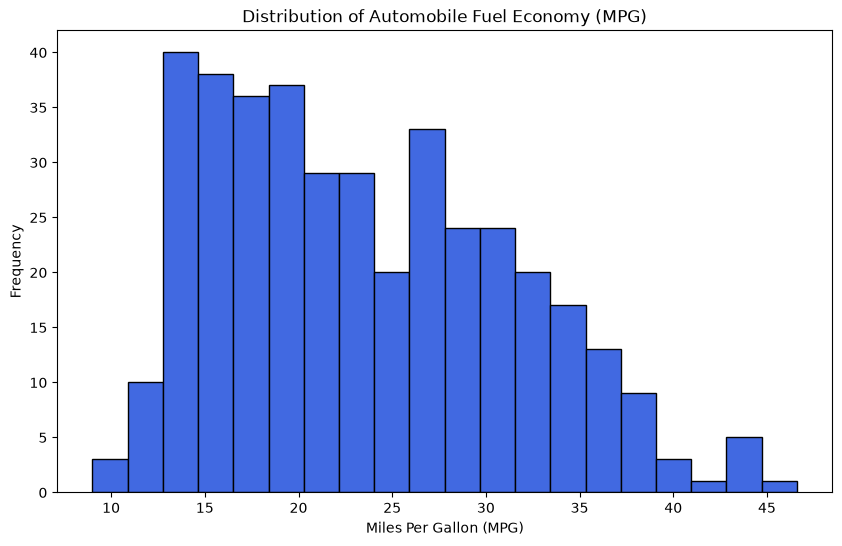

Interpretation: The distribution of MPG is slightly right-skewed, with most vehicles achieving between 15 and 30 MPG and fewer vehicles reaching above 40 MPG.



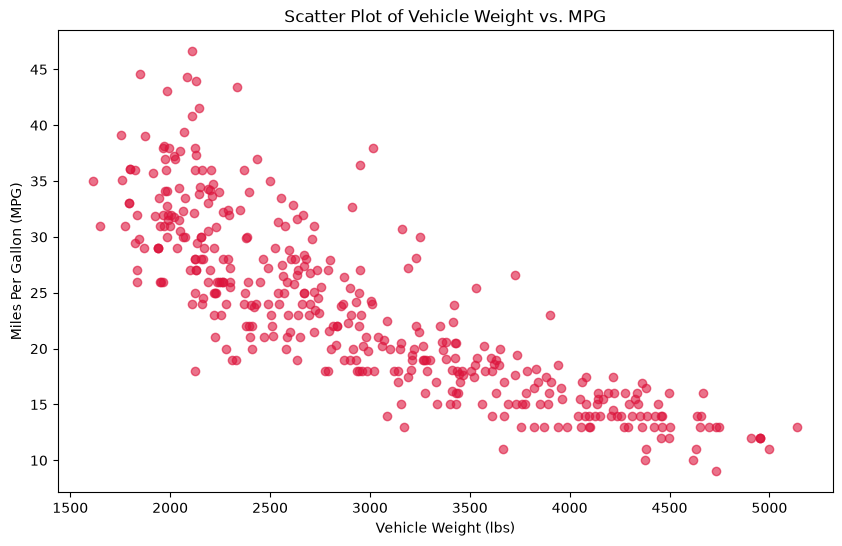

Interpretation: The scatter plot shows a strong NEGATIVE relationship between vehicle weight and MPG. As vehicle weight increases, fuel economy steadily decreases in a slightly curved pattern.



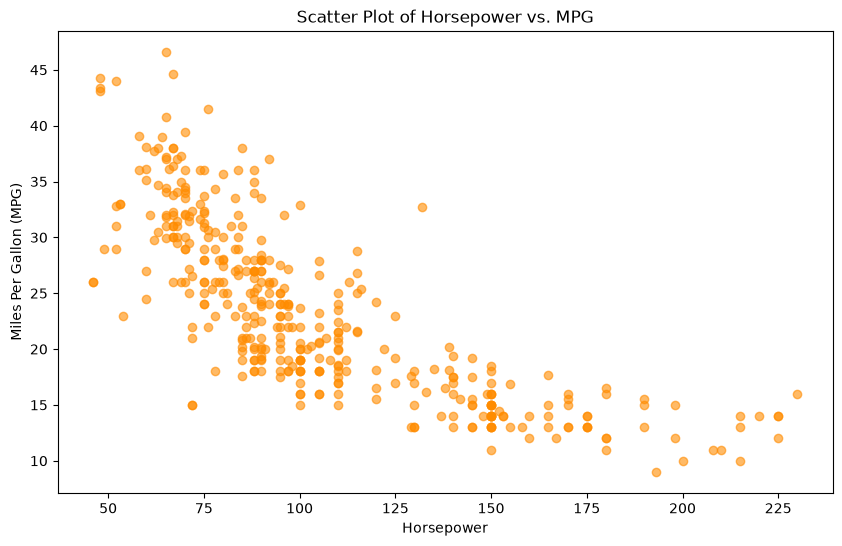

Interpretation: The scatter plot demonstrates a strong NEGATIVE relationship between horsepower and MPG. Vehicles with higher horsepower consistently exhibit lower fuel efficiency.



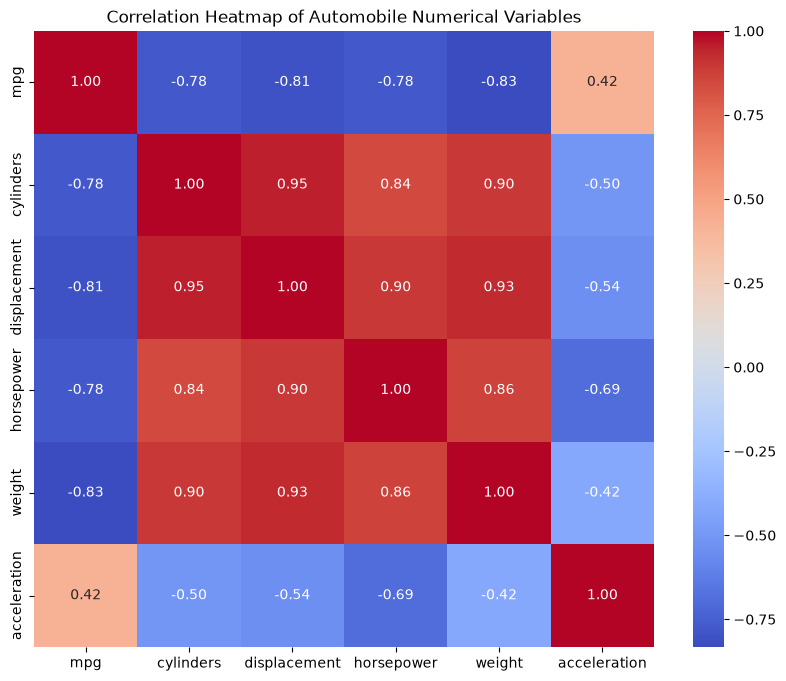

Interpretation: The heatmap highlights strong positive correlations among cylinders, displacement, horsepower, and weight, while all four of those variables are strongly negatively correlated with MPG.


In [5]:
# Q4D

# 1. Histogram showing the distribution of MPG
plt.figure(figsize=(10, 6))
plt.hist(q4_dataset['mpg'], bins=20, color='royalblue', edgecolor='black')
plt.title('Distribution of Automobile Fuel Economy (MPG)')
plt.xlabel('Miles Per Gallon (MPG)')
plt.ylabel('Frequency')
plt.show()
print('Interpretation: The distribution of MPG is slightly right-skewed, with most vehicles achieving between 15 and 30 MPG and fewer vehicles reaching above 40 MPG.\n')

# 2. Scatter plot of vehicle weight versus MPG
plt.figure(figsize=(10, 6))
plt.scatter(q4_dataset['weight'], q4_dataset['mpg'], color='crimson', alpha=0.6)
plt.title('Scatter Plot of Vehicle Weight vs. MPG')
plt.xlabel('Vehicle Weight (lbs)')
plt.ylabel('Miles Per Gallon (MPG)')
plt.show()
print('Interpretation: The scatter plot shows a strong NEGATIVE relationship between vehicle weight and MPG. As vehicle weight increases, fuel economy steadily decreases in a slightly curved pattern.\n')

# 3. Scatter plot of horsepower versus MPG
plt.figure(figsize=(10, 6))
plt.scatter(q4_dataset['horsepower'], q4_dataset['mpg'], color='darkorange', alpha=0.6)
plt.title('Scatter Plot of Horsepower vs. MPG')
plt.xlabel('Horsepower')
plt.ylabel('Miles Per Gallon (MPG)')
plt.show()
print('Interpretation: The scatter plot demonstrates a strong NEGATIVE relationship between horsepower and MPG. Vehicles with higher horsepower consistently exhibit lower fuel efficiency.\n')

# 4. Correlation heatmap for the numerical variables
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Automobile Numerical Variables')
plt.show()
print('Interpretation: The heatmap highlights strong positive correlations among cylinders, displacement, horsepower, and weight, while all four of those variables are strongly negatively correlated with MPG.')

In [6]:
# Q4E

# 1. Select two automobile origin groups: Origin 1 (USA) and Origin 3 (Japan)
usa_mpg = q4_dataset[q4_dataset['origin'] == 1]['mpg']
japan_mpg = q4_dataset[q4_dataset['origin'] == 3]['mpg']

# 2. Calculate mean, median, variance, standard deviation, and quartiles of MPG for both groups
print('--- Origin 1: USA MPG Statistics ---')
print(f'Mean:     {usa_mpg.mean():.2f}')
print(f'Median:   {usa_mpg.median():.2f}')
print(f'Variance: {usa_mpg.var():.2f}')
print(f'Std Dev:  {usa_mpg.std():.2f}')
print(f'Quartiles:\n{usa_mpg.quantile([0.25, 0.50, 0.75])}\n')

print('--- Origin 3: Japan MPG Statistics ---')
print(f'Mean:     {japan_mpg.mean():.2f}')
print(f'Median:   {japan_mpg.median():.2f}')
print(f'Variance: {japan_mpg.var():.2f}')
print(f'Std Dev:  {japan_mpg.std():.2f}')
print(f'Quartiles:\n{japan_mpg.quantile([0.25, 0.50, 0.75])}\n')

# 3 & 4. State H0 and H1
print(
    'H0: There is no statistically significant difference in mean MPG between'
    ' USA automobiles and Japanese automobiles (mu_USA = mu_Japan).'
)
print(
    'H1: There is a statistically significant difference in mean MPG between'
    ' USA automobiles and Japanese automobiles (mu_USA != mu_Japan).\n'
)

# 5 & 6. Select and justify statistical test
print('Selected Test: Two-sample independent t-test (ttest_ind).')
print(
    'Justification: We are comparing the population means of a continuous'
    ' numerical variable (MPG) across two independent automobile origin groups'
    ' (USA vs. Japan).\n'
)

# 7 & 8. Use alpha = 0.05 and report test statistic and p-value
alpha = 0.05
t_stat_q4, p_val_q4 = ttest_ind(usa_mpg, japan_mpg)
print(f'Significance level (alpha): {alpha}')
print(f't-statistic: {t_stat_q4:.4f}')
print(f'p-value: {p_val_q4:.4e}\n')

# 9 & 10. State decision and interpret result in terms of fuel economy
if p_val_q4 < alpha:
  print('Decision: Reject H0.')
  print(
      'Interpretation: Because the p-value is much smaller than alpha = 0.05,'
      ' there is a statistically significant difference in mean fuel economy'
      ' between USA and Japanese automobiles. Japanese cars in this dataset'
      ' have a significantly higher average MPG (~30.45 MPG) than American'
      ' cars (~20.03 MPG). Note that this statistical association does not'
      ' imply that country of origin directly causes fuel efficiency; rather,'
      ' it reflects underlying confounding engineering factors such as vehicle'
      ' weight, cylinder count, and engine displacement.'
  )
else:
  print('Decision: Fail to reject H0.')
  print(
      'Interpretation: There is no statistically significant difference in'
      ' mean fuel economy between USA and Japanese automobiles.'
  )

--- Origin 1: USA MPG Statistics ---
Mean:     20.03
Median:   18.50
Variance: 41.48
Std Dev:  6.44
Quartiles:
0.25    15.0
0.50    18.5
0.75    24.0
Name: mpg, dtype: float64

--- Origin 3: Japan MPG Statistics ---
Mean:     30.45
Median:   31.60
Variance: 37.09
Std Dev:  6.09
Quartiles:
0.25    25.70
0.50    31.60
0.75    34.05
Name: mpg, dtype: float64

H0: There is no statistically significant difference in mean MPG between USA automobiles and Japanese automobiles (mu_USA = mu_Japan).
H1: There is a statistically significant difference in mean MPG between USA automobiles and Japanese automobiles (mu_USA != mu_Japan).

Selected Test: Two-sample independent t-test (ttest_ind).
Justification: We are comparing the population means of a continuous numerical variable (MPG) across two independent automobile origin groups (USA vs. Japan).

Significance level (alpha): 0.05
t-statistic: -12.6649
p-value: 4.1728e-30

Decision: Reject H0.
Interpretation: Because the p-value is much smaller tha